# Explore black carbon measurements
Run the cells from top to bottom using **Run All**. This notebook reads the CSV in chunks so the entire file does not need to fit in memory.

Full-file results include missing values, sensor coverage, date coverage and daily BC means. Distributions, quantiles and correlations use a reproducible random sample of up to 50,000 rows from across the entire file. The source CSV is never modified.

The file does not specify measurement units or the timestamp timezone, so labels retain source units and timestamps. Negative BC values are flagged but retained. Confirm the instrument's quality-control rules before removing measurements.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# If imports fail, run this in a new cell: %pip install pandas numpy matplotlib
DATA_DIR = Path.cwd()  # Folder containing this notebook and the CSV
CSV_PATH = DATA_DIR / "Black Carbon Concentrations.csv"
CHUNK_SIZE = 100_000
SAMPLE_SIZE = 50_000
RANDOM_SEED = 42

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})
files = sorted(DATA_DIR.rglob("*.csv"))
display(pd.DataFrame([{"file": str(p.relative_to(DATA_DIR)),
                       "size_MB": round(p.stat().st_size / 1_000_000, 2)} for p in files]))
if not CSV_PATH.is_file():
    raise FileNotFoundError(f"Update DATA_DIR or CSV_PATH. File not found: {CSV_PATH}")

/opt/homebrew/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


,file,size_MB
0,Black Carbon Concentrations.csv,665.6


## Preview the source
This preview shows the first ten rows only. The analysis below scans the complete file.

In [2]:
preview = pd.read_csv(CSV_PATH, nrows=10)
display(preview)
display(preview.dtypes.rename("preview_dtype").to_frame())

,SensorID,date,Temperature,RH,Sense,Reference,Attenuation,BC,Smoothed,Latitude,Longitude
0,AL80-0004,2026-01-10 19:44:56,19.467079,22.839552,907982,815159,-10.784137,3518.404785,NaN,38.124436,-122.26801
1,AL80-0004,2026-01-10 19:45:56,19.808884,22.839552,905043,812624,-10.771394,5314.596680,NaN,38.124436,-122.26801
2,AL80-0004,2026-01-10 19:46:56,20.177383,22.839552,901669,809594,-10.771461,-27.841774,NaN,38.124436,-122.26801
3,AL80-0004,2026-01-10 19:47:56,20.551231,22.839552,898176,806504,-10.765718,2394.790283,NaN,38.124436,-122.26801
4,AL80-0004,2026-01-10 19:48:56,20.914398,22.839552,894945,803640,-10.761086,1932.219116,NaN,38.124436,-122.26801
5,AL80-0004,2026-01-10 19:49:56,21.250862,22.839552,891780,800820,-10.758327,1150.660767,NaN,38.124436,-122.26801
6,AL80-0004,2026-01-10 19:50:56,21.544594,22.839552,888860,798244,-10.752542,2412.290771,NaN,38.124436,-122.26801
7,AL80-0004,2026-01-10 19:51:56,21.827652,22.839552,886082,795757,-10.751563,408.478607,NaN,38.124436,-122.26801
8,AL80-0004,2026-01-10 19:52:56,22.105362,22.839552,883475,793439,-10.748633,1221.856079,NaN,38.124436,-122.26801
9,AL80-0004,2026-01-10 19:53:56,22.409782,22.839552,881194,791416,-10.745406,1345.950928,NaN,38.124436,-122.26801


,preview_dtype
SensorID,str
date,str
Temperature,float64
RH,float64
Sense,int64
Reference,int64
Attenuation,float64
BC,float64
Smoothed,float64
Latitude,float64


## Scan the complete file
`NA` and other standard pandas missing-value markers are read as missing. Numeric parsing failures and nonfinite values are counted separately and excluded from numeric summaries. Unparseable dates are excluded from daily summaries. No rows are dropped from total row counts.

Each row gets a random priority; keeping the 50,000 smallest priorities gives a uniform sample across all chunks. Daily means are calculated from sums and valid counts, rather than averaging chunk means.

In [3]:
NUMERIC_COLUMNS = ["Temperature", "RH", "Sense", "Reference", "Attenuation",
                   "BC", "Smoothed", "Latitude", "Longitude"]
rng = np.random.default_rng(RANDOM_SEED)
row_count = 0
missing = pd.Series(0, index=preview.columns, dtype="int64")
invalid_numeric = pd.Series(0, index=NUMERIC_COLUMNS, dtype="int64")
nonfinite = invalid_numeric.copy()
invalid_dates = negative_bc = 0
sensor_parts, daily_parts = [], []
sample = pd.DataFrame()

for chunk_number, chunk in enumerate(pd.read_csv(CSV_PATH, chunksize=CHUNK_SIZE,
                                                dtype="string"), start=1):
    row_count += len(chunk)
    missing += chunk.isna().sum()
    raw_date = chunk["date"]
    chunk["date"] = pd.to_datetime(raw_date, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    invalid_dates += int((raw_date.notna() & chunk["date"].isna()).sum())
    for col in NUMERIC_COLUMNS:
        raw = chunk[col]
        values = pd.to_numeric(raw, errors="coerce").astype(float)
        invalid_numeric[col] += int((raw.notna() & values.isna()).sum())
        nonfinite[col] += int(np.isinf(values).sum())
        chunk[col] = values.replace([np.inf, -np.inf], np.nan)
    negative_bc += int(chunk["BC"].lt(0).sum())

    sensor_parts.append(chunk.groupby("SensorID", dropna=False).agg(
        rows=("BC", "size"), valid_BC=("BC", "count"),
        BC_sum=("BC", "sum"), first_date=("date", "min"), last_date=("date", "max")))
    daily_parts.append(chunk.assign(day=chunk["date"].dt.floor("D")).groupby(
        ["SensorID", "day"], dropna=False).agg(
        rows=("BC", "size"), valid_BC=("BC", "count"), BC_sum=("BC", "sum")))

    chunk["_priority"] = rng.random(len(chunk))
    sample = pd.concat([sample, chunk], ignore_index=True).nsmallest(SAMPLE_SIZE, "_priority")
    if chunk_number % 10 == 0:
        print(f"Scanned {row_count:,} rows...")

if row_count == 0:
    raise ValueError("The CSV has headers but no data rows.")
sample = sample.drop(columns="_priority").reset_index(drop=True)
sensors = pd.concat(sensor_parts).groupby(level=0, dropna=False).agg(
    rows=("rows", "sum"), valid_BC=("valid_BC", "sum"), BC_sum=("BC_sum", "sum"),
    first_date=("first_date", "min"), last_date=("last_date", "max"))
sensors["mean_BC"] = sensors.pop("BC_sum") / sensors["valid_BC"].replace(0, np.nan)
sensors = sensors.sort_values("rows", ascending=False)
daily = pd.concat(daily_parts).groupby(level=[0, 1], dropna=False).sum().reset_index()
daily = daily.loc[daily["day"].notna()].copy()
daily["mean_BC"] = daily.pop("BC_sum") / daily["valid_BC"].replace(0, np.nan)
quality = pd.DataFrame({"missing": missing, "missing_pct": missing / row_count * 100,
                        "invalid_numeric": invalid_numeric, "nonfinite_numeric": nonfinite})
quality[["invalid_numeric", "nonfinite_numeric"]] = quality[["invalid_numeric", "nonfinite_numeric"]].fillna(0).astype(int)
print(f"Finished: {row_count:,} rows; {len(sample):,} sampled rows.")

Scanned 1,000,000 rows...
Scanned 2,000,000 rows...
Scanned 3,000,000 rows...
Scanned 4,000,000 rows...
Scanned 5,000,000 rows...
Scanned 6,000,000 rows...
Finished: 6,059,765 rows; 50,000 sampled rows.


## Full-file coverage and quality

,value
total_rows,6059765
identified_sensors,27
first_timestamp,2025-12-01 07:00:02
last_timestamp,2026-09-21 06:59:57
unparseable_dates,63
negative_BC_rows,2395127
negative_BC_pct_of_valid,39.525081


,missing,missing_pct,invalid_numeric,nonfinite_numeric
Latitude,3388529,55.918489,0,0
Longitude,3388529,55.918489,0,0
Smoothed,585614,9.663972,0,0
Attenuation,0,0.000000,0,0
BC,0,0.000000,0,0
RH,0,0.000000,0,0
Reference,0,0.000000,0,0
Sense,0,0.000000,0,0
SensorID,0,0.000000,0,0
Temperature,0,0.000000,0,0


,rows,valid_BC,first_date,last_date,mean_BC
SensorID,,,,,
AL80-0035,1324313,1324313,2026-02-12 02:08:32,2026-07-14 10:17:07,228.072507
AL80-0024,406074,406074,2025-12-01 07:00:57,2026-09-21 06:59:10,312.371302
AL80-0031,402181,402181,2025-12-01 07:00:02,2026-07-07 04:43:02,224.731611
AL80-0004,305500,305500,2026-01-10 19:44:56,2026-09-21 06:59:43,333.559428
AL80-0009,301388,301388,2026-02-11 23:51:34,2026-09-21 06:59:37,213.005730
AL80-0033,273203,273203,2026-02-07 22:09:07,2026-09-21 06:59:49,228.691030
AL80-0021,243596,243596,2026-02-12 00:05:54,2026-09-19 09:05:38,204.819447
AL80-0030,235287,235287,2026-01-20 00:00:02,2026-08-25 10:14:10,308.402462
AL80-0012,230020,230020,2026-02-11 23:03:09,2026-08-11 01:17:36,202.939484


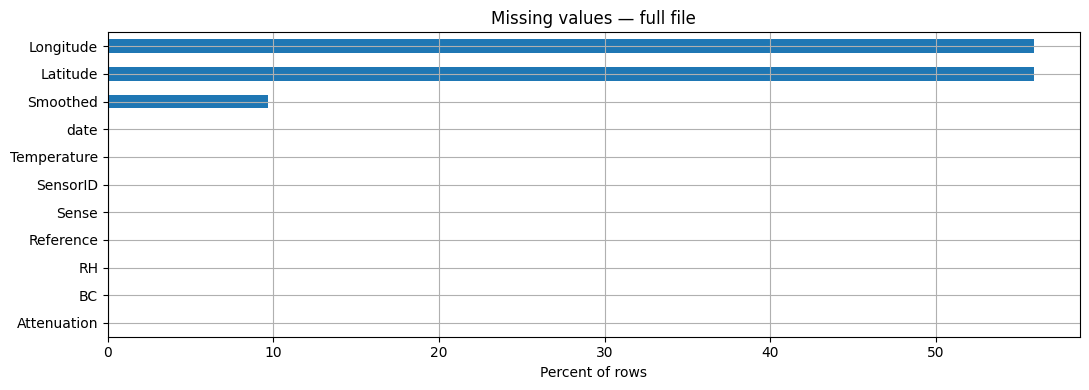

In [4]:
display(pd.Series({
    "total_rows": row_count,
    "identified_sensors": int(sensors.index.notna().sum()),
    "first_timestamp": sensors["first_date"].min(),
    "last_timestamp": sensors["last_date"].max(),
    "unparseable_dates": invalid_dates,
    "negative_BC_rows": negative_bc,
    "negative_BC_pct_of_valid": 100 * negative_bc / sensors["valid_BC"].sum()
        if sensors["valid_BC"].sum() else np.nan,
}).to_frame("value"))
display(quality.sort_values("missing_pct", ascending=False))
display(sensors)
quality["missing_pct"].sort_values().plot.barh(title="Missing values — full file", xlabel="Percent of rows")
plt.tight_layout()
plt.show()

## Sample statistics and distributions
These quantiles describe the random sample, not exact full-file quantiles. The histogram uses a symmetric log x-axis to retain negative values and make extreme values visible.

,count,mean,std,min,1%,5%,50%,95%,99%,max
Temperature,50000.0,30.981640,6.510954,1.395552e+01,21.117340,23.264290,29.160370,43.323799,4.358554e+01,5.320935e+01
RH,50000.0,32.272768,9.238471,-6.000000e+00,13.604010,15.494240,33.789806,43.322880,4.678098e+01,1.190000e+02
Sense,50000.0,579533.190440,168642.373706,1.132140e+05,193033.850000,295908.450000,608716.500000,829761.350000,9.123771e+05,1.048575e+06
Reference,50000.0,824393.680900,80403.292573,5.648700e+05,669212.930000,700453.250000,813049.000000,949128.050000,1.009619e+06,1.048575e+06
Attenuation,50000.0,39.770060,35.607205,-2.478245e+01,-12.116020,-3.678390,31.660342,104.107876,1.454557e+02,1.866213e+02
BC,50000.0,270.514867,2178.749500,-4.335864e+04,-4749.142735,-2014.908764,254.553360,2536.212646,5.760342e+03,9.207195e+04
Smoothed,45129.0,-38.381200,31855.268511,-3.836066e+06,-4974.754121,-2025.756079,0.000000,2320.440039,5.738632e+03,3.966616e+05
Latitude,22083.0,38.102726,0.017845,3.806657e+01,38.066572,38.066572,38.103876,38.126121,3.813244e+01,3.814026e+01
Longitude,22083.0,-122.238654,0.023288,-1.222753e+02,-122.275333,-122.275333,-122.239270,-122.200120,-1.222001e+02,-1.222001e+02


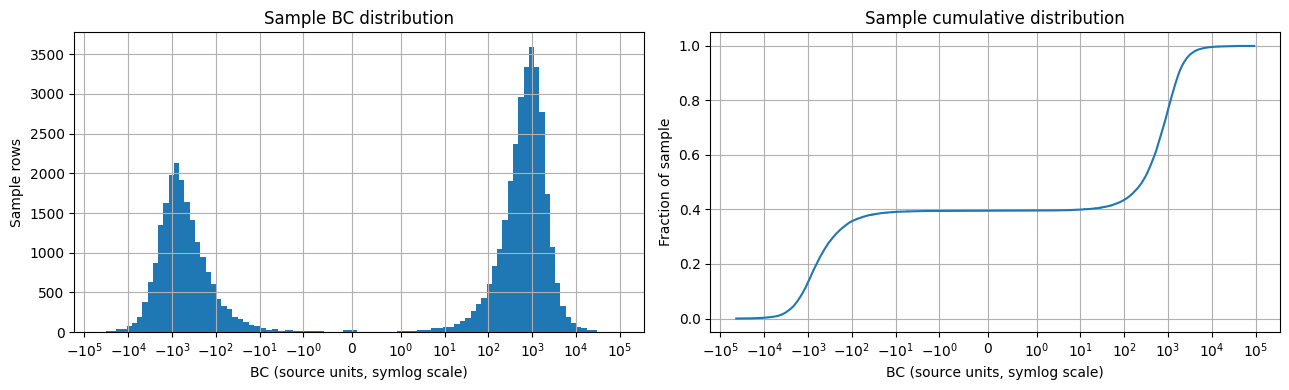

In [5]:
display(sample[NUMERIC_COLUMNS].describe(percentiles=[.01, .05, .5, .95, .99]).T)
bc = sample["BC"].dropna()
if not bc.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    # Transform bin edges too, so extreme values do not collapse the center into one bin.
    transformed = np.sign(bc) * np.log1p(np.abs(bc))
    edges = np.linspace(transformed.min() - 1e-9, transformed.max() + 1e-9, 81)
    bins = np.sign(edges) * np.expm1(np.abs(edges))
    axes[0].hist(bc, bins=bins)
    axes[0].set_xscale("symlog", linthresh=1)
    axes[0].set(title="Sample BC distribution", xlabel="BC (source units, symlog scale)", ylabel="Sample rows")
    ordered = np.sort(bc)
    axes[1].plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered))
    axes[1].set_xscale("symlog", linthresh=1)
    axes[1].set(title="Sample cumulative distribution", xlabel="BC (source units, symlog scale)", ylabel="Fraction of sample")
    plt.tight_layout()
    plt.show()

## Daily patterns by sensor
Full-file daily means and measurement counts for the five sensors with the most rows. Means include negative BC readings and are weighted by observations, not elapsed time. Missing days appear as gaps; counts help identify uneven coverage.

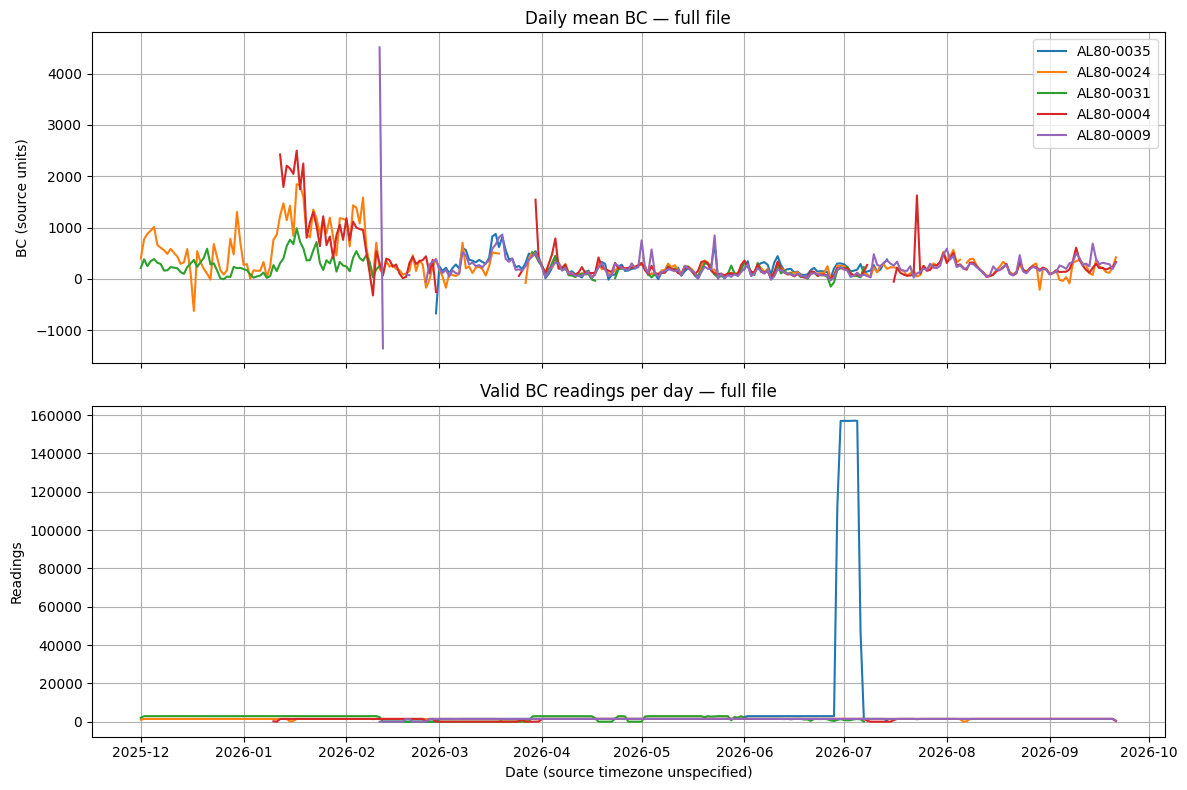

In [6]:
top_sensors = sensors.loc[sensors.index.notna()].head(5).index
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for sensor in top_sensors:
    series = daily.loc[daily["SensorID"].eq(sensor)].set_index("day").sort_index()
    if series.empty:
        continue
    series = series.reindex(pd.date_range(series.index.min(), series.index.max(), freq="D"))
    axes[0].plot(series.index, series["mean_BC"], label=sensor)
    axes[1].plot(series.index, series["valid_BC"].fillna(0), label=sensor)
axes[0].set(title="Daily mean BC — full file", ylabel="BC (source units)")
axes[1].set(title="Valid BC readings per day — full file", ylabel="Readings", xlabel="Date (source timezone unspecified)")
if axes[0].lines:
    axes[0].legend()
plt.tight_layout()
plt.show()

## Explore relationships
Sample-based Pearson correlations use pairwise complete observations. Combined-sensor relationships can reflect sensor differences or time trends and do not establish causation.

,Temperature,RH,Sense,Reference,Attenuation,BC,Smoothed,Latitude,Longitude
Temperature,1.00,-0.82,-0.29,-0.34,0.17,0.00,0.01,-0.16,-0.11
RH,-0.82,1.00,0.24,0.23,-0.15,-0.01,-0.01,0.15,0.04
Sense,-0.29,0.24,1.00,-0.09,-0.94,0.02,-0.01,0.11,-0.08
Reference,-0.34,0.23,-0.09,1.00,0.36,0.01,0.00,-0.06,-0.06
Attenuation,0.17,-0.15,-0.94,0.36,1.00,-0.01,0.01,-0.14,0.05
BC,0.00,-0.01,0.02,0.01,-0.01,1.00,0.05,-0.01,0.00
Smoothed,0.01,-0.01,-0.01,0.00,0.01,0.05,1.00,-0.00,-0.01
Latitude,-0.16,0.15,0.11,-0.06,-0.14,-0.01,-0.00,1.00,-0.48
Longitude,-0.11,0.04,-0.08,-0.06,0.05,0.00,-0.01,-0.48,1.00


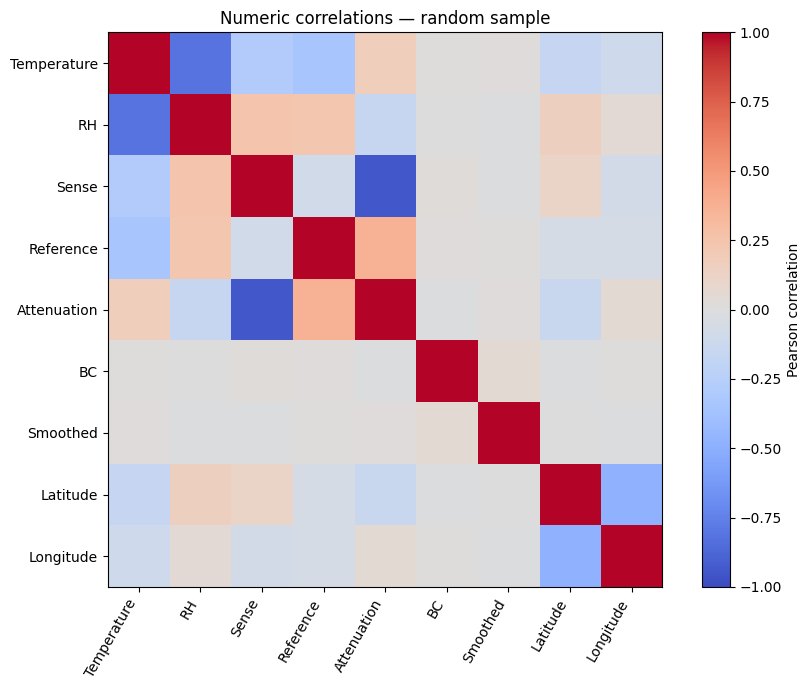

In [7]:
correlations = sample[NUMERIC_COLUMNS].corr()
display(correlations.round(2))
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(NUMERIC_COLUMNS)), NUMERIC_COLUMNS, rotation=60, ha="right")
ax.set_yticks(range(len(NUMERIC_COLUMNS)), NUMERIC_COLUMNS)
ax.grid(False)
ax.set_title("Numeric correlations — random sample")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

## Your own exploration
Change `SENSOR` to one of the sensor IDs above. `sample` holds sampled observations, `sensors` contains full-file sensor summaries, and `daily` contains full-file daily aggregates. Sampled observations do not support exact duplicate checks or measurement-interval analysis.

In [8]:
SENSOR = top_sensors[0] if len(top_sensors) else None
sensor_sample = sample.loc[sample["SensorID"].eq(SENSOR)].sort_values("date")
display(sensor_sample.head(20))
# Examples to try:
# display(sample.nlargest(20, "BC"))
# display(daily.loc[daily["SensorID"].eq(SENSOR)])
# display(sample.loc[sample["BC"].lt(0)].head(20))

,SensorID,date,Temperature,RH,Sense,Reference,Attenuation,BC,Smoothed,Latitude,Longitude
12166,AL80-0035,2026-02-28 23:41:02,35.254066,36.233158,863957.0,772103.0,-11.240504,-711.270935,0.0,38.099471,-122.20012
40290,AL80-0035,2026-03-01 00:27:02,35.109863,35.960403,865226.0,773413.0,-11.217755,29.890736,0.0,38.099471,-122.20012
42170,AL80-0035,2026-03-01 07:20:58,26.538109,43.845501,939997.0,844575.0,-10.704314,525.498352,0.0,38.099471,-122.20012
28991,AL80-0035,2026-03-01 10:09:56,24.946594,45.464867,953415.0,857899.0,-10.556390,584.199951,0.0,38.099471,-122.20012
26006,AL80-0035,2026-03-01 10:18:56,24.877167,45.228352,954126.0,858582.0,-10.551354,-7.318409,0.0,38.099471,-122.20012
3858,AL80-0035,2026-03-01 10:48:56,24.599449,44.907913,956797.0,861102.0,-10.537828,-767.195557,0.0,38.099471,-122.20012
2730,AL80-0035,2026-03-01 15:10:53,24.359123,48.329746,957153.0,862980.0,-10.357174,494.000641,0.0,38.099471,-122.20012
13308,AL80-0035,2026-03-01 17:35:53,25.272377,47.355076,947854.0,855161.0,-10.291073,339.404480,0.0,38.099471,-122.20012
34800,AL80-0035,2026-03-01 20:26:51,29.977493,41.636761,903087.0,815297.0,-10.226643,-576.601929,0.0,38.099471,-122.20012
6623,AL80-0035,2026-03-01 21:04:50,31.141754,38.031815,892305.0,805568.0,-10.226038,593.957825,0.0,38.099471,-122.20012
